In [1]:
# Settings and data
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Ellipse
from matplotlib.ticker import FuncFormatter, NullFormatter, MaxNLocator, MultipleLocator
from numpy.polynomial import Polynomial
from scipy.stats import chi2, spearmanr
from IPython.display import display

PROJECT_DIR = Path.home() / "Anastasia_Morfiadakis_MESA" / "Data"
FIGURES_DIR = PROJECT_DIR / "figures" / "REEfit"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

REE = ["La", "Ce", "Pr", "Nd", "Sm", "Eu", "Gd", "Tb", "Dy", "Ho", "Er", "Tm", "Yb", "Lu"]
IONIC_RADII = np.array([1.160, 1.143, 1.126, 1.109, 1.079, 1.066, 1.053,
                        1.040, 1.027, 1.015, 1.004, 0.994, 0.985, 0.977])
CI = np.array([0.2414, 0.6194, 0.0939, 0.4737, 0.1536, 0.05883, 0.2069,
               0.03797, 0.2558, 0.05644, 0.1655, 0.02609, 0.1687, 0.02503])
RSD_FLOOR, LOD_SIGMA_PPM = 0.10, 0.005
MIN_REE = 6
LAMBDA_COLS = [f"lambda{k}" for k in range(5)]

THESIS_RC = {
    "font.family": "serif", "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "mathtext.fontset": "stix", "font.size": 15,
    "axes.labelsize": 15, "axes.titlesize": 15, "xtick.labelsize": 15, "ytick.labelsize": 15,
    "legend.fontsize": 16, "figure.titlesize": 16, "figure.dpi": 150,
    "axes.facecolor": "white", "figure.facecolor": "white", "axes.edgecolor": "0.35", "axes.linewidth": 1,
    "grid.color": "0.88", "grid.linewidth": 0.6, "axes.unicode_minus": False,
}
plt.rcParams.update(THESIS_RC)
COL = {"data": "#4A4A4A", "fit": "#D95F8D", "random": "#6E90F2", "degree0": "#777777", "degree1": "#27B7B0",
       "degree2": "#6E90F2", "degree3": "#F28E2B", "degree4": "#E75A9D"}
DATA_STYLE = {"NVP": ("Newer Volcanics Province", COL["random"]), "Abyssal LA-ICP-MS": ("Abyssal peridotites", COL["fit"])}
UNC_COL = {"random_unc": "#009E73", "systematic_unc": "#D55E00"}

XENOLITH_FILE = PROJECT_DIR / "Summary Data SE Aus xenoliths.xlsx"
raw = pd.read_excel(XENOLITH_FILE, sheet_name="Cpx", header=None)
blocks = []
for first, last, col in [(4, 359, 45), (364, 551, 48), (555, 653, 42)]:
    block = raw.iloc[first - 1:last]
    out = block.iloc[:, col - 1:col - 1 + len(REE)].apply(pd.to_numeric, errors="coerce").set_axis(REE, axis=1)
    out["analysis_id"] = block.iloc[:, 0].astype("string").str.strip()
    blocks.append(out)
df = pd.concat(blocks, ignore_index=True)
df[REE] = df[REE].where(df[REE] > 0)
df = df[~df["analysis_id"].fillna("").str.lower().isin(["", "average", "sample"])
        & df[REE].notna().sum(axis=1).ge(MIN_REE)].copy()
from openpyxl import load_workbook
ws = load_workbook(XENOLITH_FILE)["Cpx"]
RZ_IDS = {str(c.value).strip() for c in ws["A"] if c.value is not None and c.font.i}
secondary = (df["analysis_id"].isin(RZ_IDS) | df["analysis_id"].str.contains("RZ", na=False)
             | df["analysis_id"].str.startswith("76996-cpx2", na=False))
df = df[~secondary].copy()
df["sample_id"] = df["analysis_id"].astype(str) + " [" + (df.groupby("analysis_id").cumcount() + 1).astype(str) + "]"

abyssal = pd.read_excel(PROJECT_DIR / "Abyssal_Cpx.xlsx", sheet_name="LA-ICP-MS")[["sample_id"] + REE]
combined_ree = pd.concat([df[["sample_id"] + REE].assign(dataset="NVP"), abyssal.assign(dataset="Abyssal LA-ICP-MS")],
                         ignore_index=True)
combined_ree[REE] = combined_ree[REE].apply(pd.to_numeric, errors="coerce")
combined_ree[REE] = combined_ree[REE].where(combined_ree[REE] > 0)
ppm_all = combined_ree[REE].to_numpy(float)
print(combined_ree["dataset"].value_counts().to_dict(), "| total:", len(combined_ree))

{'NVP': 462, 'Abyssal LA-ICP-MS': 51} | total: 513


In [2]:
# Orthogonal polynomial basis, uncertainty model and lambda fits
def calculate_full_ree_polynomials(radii=IONIC_RADII, degree=4):
    polynomials = []
    for n in range(degree + 1):
        p = Polynomial([0] * n + [1])
        for q in polynomials:
            p = p - (np.sum(p(radii) * q(radii)) / np.sum(q(radii) ** 2)) * q
        polynomials.append(p / p.coef[-1])
    return polynomials


FULL_REE_POLYNOMIALS = calculate_full_ree_polynomials()


def full_ree_basis(r):
    return np.column_stack([p(np.asarray(r, float)) for p in FULL_REE_POLYNOMIALS])


def ln_ci_normalise(ppm, ci=CI):
    return np.log(np.asarray(ppm, float) / ci)


def sigma_ln_from_ppm(ppm, lod_sigma_ppm=LOD_SIGMA_PPM):
    ppm = np.asarray(ppm, float)
    ppm = np.where(ppm > 0, ppm, np.nan)
    return np.sqrt((RSD_FLOOR * ppm) ** 2 + lod_sigma_ppm ** 2) / ppm


def fit_lambda(ppm, exclude=(), degree=4, lod_sigma_ppm=LOD_SIGMA_PPM):
    ppm = np.asarray(ppm, float)
    good = np.isfinite(ppm) & (ppm > 0) & ~np.isin(REE, list(exclude))
    if good.sum() <= degree:
        raise ValueError(f"Need at least {degree + 1} positive REEs.")
    y, sigma = ln_ci_normalise(ppm[good], CI[good]), sigma_ln_from_ppm(ppm[good], lod_sigma_ppm)
    A = full_ree_basis(IONIC_RADII[good])[:, :degree + 1]
    Aw = A / sigma[:, None]
    lambdas = np.linalg.lstsq(Aw, y / sigma, rcond=None)[0]
    return dict(lambdas=lambdas, cov=np.linalg.pinv(Aw.T @ Aw), sigma=sigma,
                BIC=np.sum(((y - A @ lambdas) / sigma) ** 2) + len(lambdas) * np.log(len(y)))


def reconstruct_ppm(lambdas):
    return CI * np.exp(full_ree_basis(IONIC_RADII)[:, :len(lambdas)] @ np.asarray(lambdas, float))


def iqr_of(values):
    x = np.asarray(values, float)
    q75, q25 = np.percentile(x[np.isfinite(x)], [75, 25])
    return q75 - q25


A_full = full_ree_basis(IONIC_RADII)
G = A_full.T @ A_full
for n, p in enumerate(FULL_REE_POLYNOMIALS[1:], start=1):
    print(f"f{n} roots:", ", ".join(f"{x:.6f}" for x in np.sort(p.roots())))
print(f"Maximum |off-diagonal R_basis|: {np.abs(G / np.sqrt(np.outer(np.diag(G), np.diag(G))) - np.eye(5)).max():.2e}")
print("Assigned uncertainty:", ", ".join(f"{c:g} ppm {100 * sigma_ln_from_ppm(c):.0f}%" for c in (1, 0.1, 0.01)))

fits = [fit_lambda(p) for p in ppm_all]
combined_lambda = combined_ree[["sample_id", "dataset"]].assign(
    **{f"lambda{i}": [f["lambdas"][i] for f in fits] for i in range(5)},
    **{f"lambda_cov_{i}{j}": [f["cov"][i, j] for f in fits] for i in range(5) for j in range(5)})
POPULATION_IQR = pd.Series({k: iqr_of(combined_lambda[f"lambda{k}"]) for k in range(5)}, name="population IQR")
display(POPULATION_IQR.to_frame().T.round(3))

f1 roots: 1.055571
f2 roots: 1.007224, 1.125508
f3 roots: 0.991432, 1.061522, 1.145500
f4 roots: 0.985134, 1.033452, 1.100546, 1.153044
Maximum |off-diagonal R_basis|: 1.39e-10
Assigned uncertainty: 1 ppm 10%, 0.1 ppm 11%, 0.01 ppm 51%


,0,1,2,3,4
population IQR,1.234,9.234,110.209,805.914,8689.959


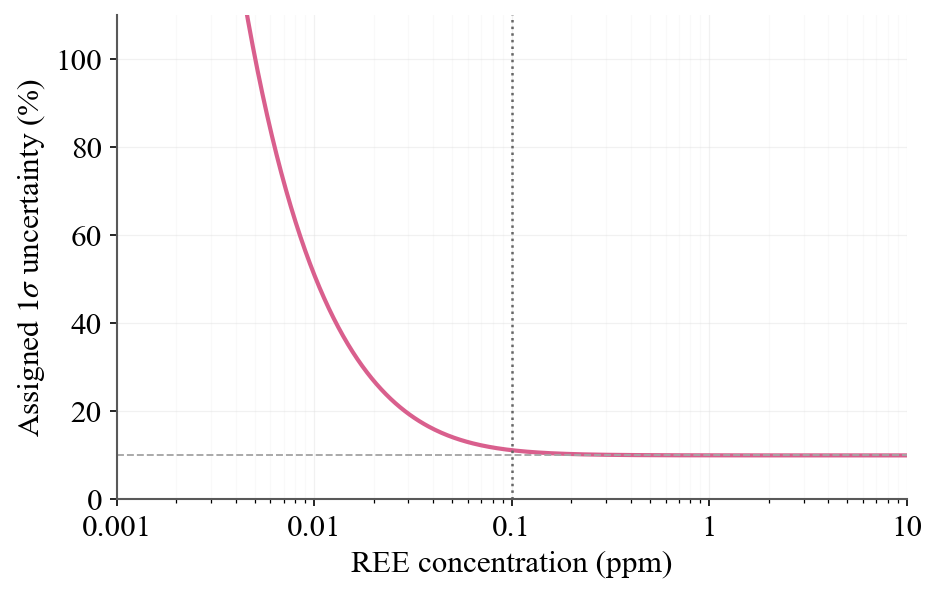

In [3]:
# Figure 3.3
conc = np.logspace(-3, 1, 500)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.plot(conc, 100 * sigma_ln_from_ppm(conc), color=COL["fit"], lw=2.0)
ax.axvline(0.1, color="0.40", ls=":", lw=1.2)
ax.axhline(100 * RSD_FLOOR, color="0.65", ls="--", lw=0.9)
ax.set_xscale("log")
ax.set(xlim=(0.001, 10), ylim=(0, 110), xticks=[0.001, 0.01, 0.1, 1, 10],
       xlabel="REE concentration (ppm)", ylabel=r"Assigned $1\sigma$ uncertainty (%)")
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x:g}"))
ax.xaxis.set_minor_formatter(NullFormatter())
ax.grid(which="major", alpha=0.45)
ax.grid(which="minor", alpha=0.18)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "uncertainty_model.pdf", bbox_inches="tight", facecolor="white")
plt.show()

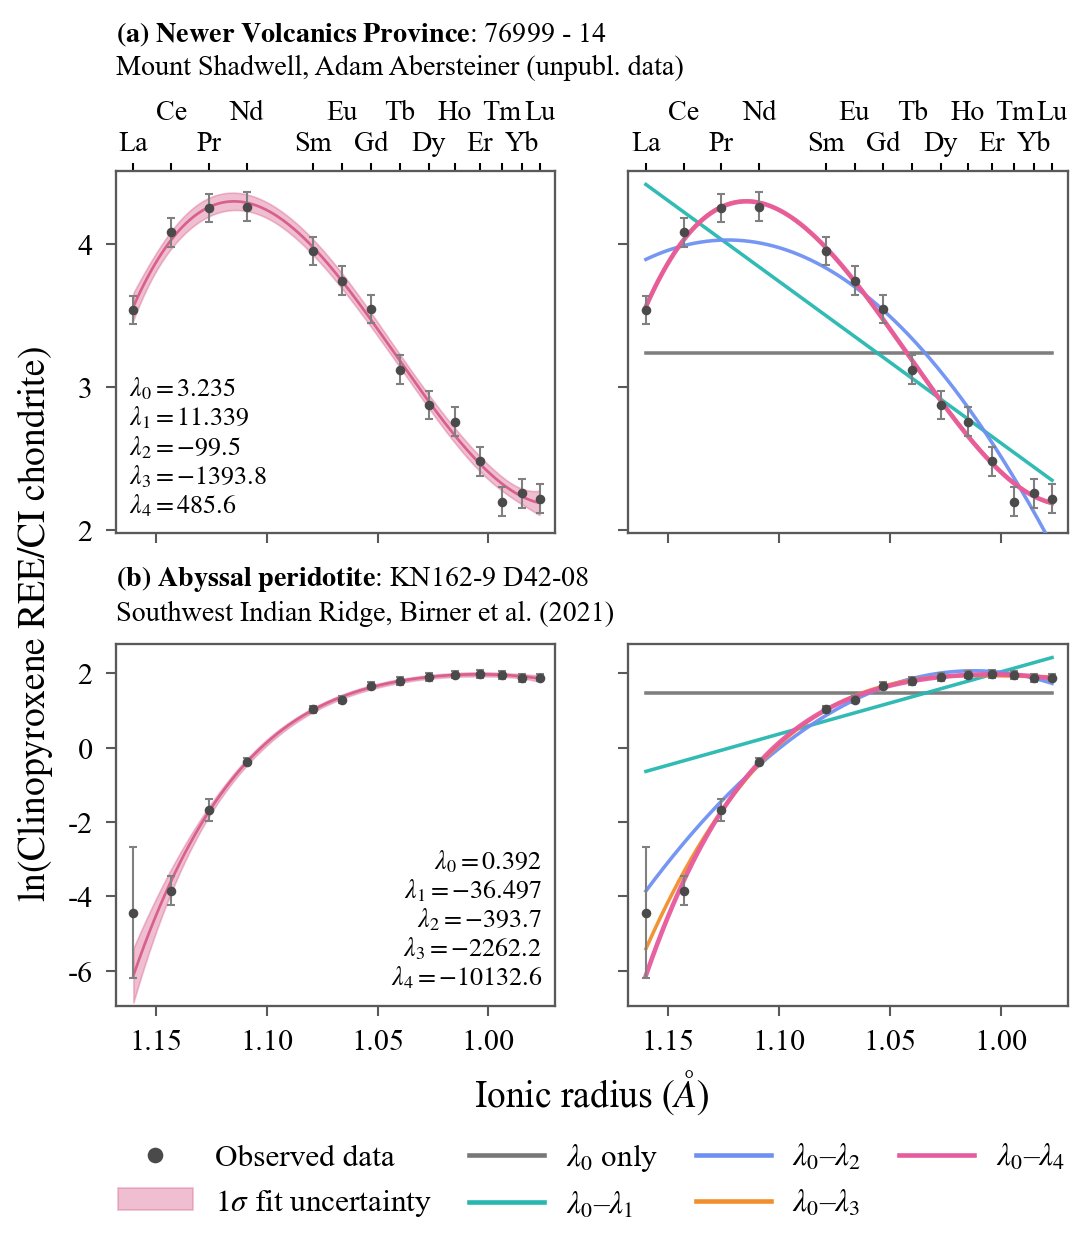

In [4]:
# Figure 3.5
EXAMPLES = ["76999 - 14 [1]", "KN162-9 D42-08 [Birner et al. (2021), id 196]"]
DATASET = dict(zip(EXAMPLES, ["Newer Volcanics Province", "Abyssal peridotite"]))
WHERE = dict(zip(EXAMPLES, ["Mount Shadwell, Adam Abersteiner (unpubl. data)", "Southwest Indian Ridge, Birner et al. (2021)"]))
LAMBDA_POS = dict(zip(EXAMPLES, [(0, "lower left"), (0, "lower right")]))
DEGREE, ENV_ALPHA, PAD = 4, 0.40, 0.10
FS = dict(axis=18, tick=14.5, ree=13.5, title=13.5, lam=12.5, legend=15)
CORNER = {"upper left": (0.03, 0.96, "left", "top"), "upper right": (0.97, 0.96, "right", "top"),
          "lower left": (0.03, 0.04, "left", "bottom"), "lower right": (0.97, 0.04, "right", "bottom")}

x_smooth = np.linspace(IONIC_RADII.max(), IONIC_RADII.min(), 400)
A_smooth = full_ree_basis(x_smooth)
ree_by_id = combined_ree.set_index("sample_id")
n = len(EXAMPLES)
fig = plt.figure(figsize=(7.2, 3.5 * n + 1.2), layout="constrained")
gs = fig.add_gridspec(2 * n + 2, 2, height_ratios=[0.2, 1] * n + [0.1, 0.22], wspace=0, hspace=0)
axes = np.empty((n, 2), dtype=object)
for r in range(n):
    for c in range(2):
        axes[r, c] = fig.add_subplot(gs[2 * r + 1, c], sharex=axes[0, 0] if (r or c) else None,
                                     sharey=axes[r, 0] if c else None)

for r, sample_id in enumerate(EXAMPLES):
    ppm = ree_by_id.loc[sample_id, REE].to_numpy(float)
    obs = np.isfinite(ppm) & (ppm > 0)
    y_obs = np.log(ppm[obs] / CI[obs])
    fit = fit_lambda(ppm, degree=DEGREE)
    y_fit = A_smooth @ fit["lambdas"]
    sigma_fit = np.sqrt(np.einsum("ij,jk,ik->i", A_smooth, fit["cov"], A_smooth))
    ax_fit, ax_deg = axes[r]
    for ax in (ax_fit, ax_deg):
        ax.errorbar(IONIC_RADII[obs], y_obs, yerr=sigma_ln_from_ppm(ppm[obs]), fmt="o", ms=3.6, color=COL["data"],
                    ecolor="0.5", elinewidth=1.0, capsize=1.8, capthick=1.0, zorder=8)
    ax_fit.fill_between(x_smooth, y_fit - sigma_fit, y_fit + sigma_fit, color=COL["fit"], alpha=ENV_ALPHA,
                        lw=0.8, edgecolor=COL["fit"], zorder=2)
    ax_fit.plot(x_smooth, y_fit, color=COL["fit"], lw=1.3, zorder=4)
    for d in range(DEGREE + 1):
        ax_deg.plot(x_smooth, A_smooth[:, :d + 1] @ fit_lambda(ppm, degree=d)["lambdas"], color=COL[f"degree{d}"],
                    lw=2.2 if d == DEGREE else 1.7, alpha=0.95, zorder=4)
    lo, hi = min(y_obs.min(), y_fit.min()), max(y_obs.max(), y_fit.max())
    ax_fit.set_ylim(lo - PAD * (hi - lo), hi + PAD * (hi - lo))

    title_ax = fig.add_subplot(gs[2 * r, :])
    title_ax.axis("off")
    name, bold = re.sub(r"\s*\[.*\]$", "", sample_id), DATASET[sample_id].replace(" ", r"\ ")
    title_ax.text(0.0, 0.5, rf"$\bf{{({chr(97 + r)})\ {bold}}}$: {name}" + f"\n{WHERE[sample_id]}", transform=title_ax.transAxes,
                  ha="left", va="center", fontsize=FS["title"], linespacing=1.3, in_layout=False)
    panel, corner = LAMBDA_POS[sample_id]
    x, y, ha, va = CORNER[corner]
    lam_text = "\n".join(rf"$\lambda_{i} = {v:.3f}$" if i <= 1 else rf"$\lambda_{i} = {v:.1f}$"
                         for i, v in enumerate(fit["lambdas"]))
    axes[r, panel].text(x, y, lam_text, transform=axes[r, panel].transAxes, ha=ha, va=va, fontsize=FS["lam"],
                        linespacing=1.12, zorder=20, in_layout=False,
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.82, pad=1.0))

for (r, c), ax in np.ndenumerate(axes):
    ax.set_xlim(1.168, 0.970)
    ax.tick_params(labelsize=FS["tick"], length=5, width=1.0, color="0.35", pad=6, direction="out",
                   labelbottom=(r == n - 1), labelleft=(c == 0))
    for spine in ax.spines.values():
        spine.set(color="0.35", linewidth=1.1)
for ax in axes[-1]:
    ax.set_xticks([1.15, 1.10, 1.05, 1.00], ["1.15", "1.10", "1.05", "1.00"])
for ax in axes[0]:
    top = ax.secondary_xaxis("top")
    top.set_xticks(IONIC_RADII, labels=[])
    top.tick_params(direction="out", length=4, width=1.0, pad=2)
    top.spines["top"].set_visible(False)
    for i, (element, radius) in enumerate(zip(REE, IONIC_RADII)):
        ax.annotate(element, xy=(radius, 1), xycoords=("data", "axes fraction"), xytext=(0, 7 if i % 2 == 0 else 22),
                    textcoords="offset points", ha="center", va="bottom", fontsize=FS["ree"], annotation_clip=False)

fig.supylabel(r"$\ln(\mathrm{Clinopyroxene\ REE}/\mathrm{CI\ chondrite})$", fontsize=FS["axis"])
xlabel_ax = fig.add_subplot(gs[-2, :])
xlabel_ax.axis("off")
xlabel_ax.text(0.5, 0.5, r"Ionic radius ($\AA$)", ha="center", va="center", fontsize=FS["axis"], transform=xlabel_ax.transAxes)
handles = [Line2D([], [], marker="o", ls="", color=COL["data"], markersize=6.5, label="Observed data"),
           Patch(facecolor=COL["fit"], alpha=ENV_ALPHA, edgecolor=COL["fit"], lw=0.8, label=r"$1\sigma$ fit uncertainty")]
handles += [Line2D([], [], color=COL[f"degree{d}"], lw=2.2, label=r"$\lambda_0$ only" if d == 0 else rf"$\lambda_0$–$\lambda_{d}$")
            for d in range(DEGREE + 1)]
legend_ax = fig.add_subplot(gs[-1, :])
legend_ax.axis("off")
legend_ax.legend(handles=handles, loc="center", ncol=4, frameon=False, fontsize=FS["legend"],
                 handlelength=2.4, handletextpad=0.7, columnspacing=1.2)
fig.savefig(FIGURES_DIR / "fit_and_degree_comparison_combined.pdf", bbox_inches="tight", facecolor="white")
plt.show()

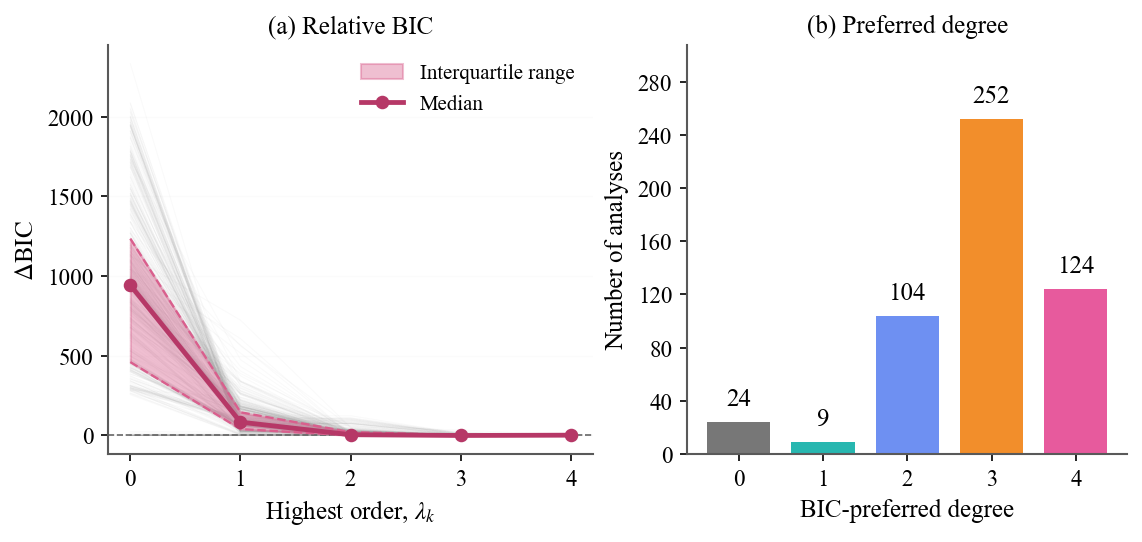

preferred degree,0,1,2,3,4,All
dataset,,,,,,
Abyssal LA-ICP-MS,0,0,13,23,15,51
NVP,24,9,91,229,109,462
All,24,9,104,252,124,513


In [5]:
# Figure 3.9
DEGREES = np.arange(5)
bic = np.array([[fit_lambda(p, degree=d)["BIC"] for d in DEGREES] for p in ppm_all])
delta = bic - bic.min(axis=1, keepdims=True)
preferred = bic.argmin(axis=1)
q25, median, q75 = np.quantile(delta, [0.25, 0.5, 0.75], axis=0)
counts = pd.Series(preferred).value_counts().reindex(DEGREES, fill_value=0)

with plt.rc_context({**THESIS_RC, "font.size": 12, "axes.labelsize": 12, "axes.titlesize": 12,
                     "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 10}):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(7.5, 3.5), gridspec_kw={"width_ratios": [1.1, 1]}, layout="constrained")
    for values in delta:
        ax1.plot(DEGREES, values, color="0.65", lw=0.45, alpha=0.06)
    ax1.fill_between(DEGREES, q25, q75, color=COL["fit"], alpha=0.40, label="Interquartile range", zorder=2)
    ax1.plot(DEGREES, q25, color=COL["fit"], lw=1.1, ls="--", zorder=3)
    ax1.plot(DEGREES, q75, color=COL["fit"], lw=1.1, ls="--", zorder=3)
    ax1.plot(DEGREES, median, "-o", color="#B63867", lw=2.3, ms=5.5, label="Median", zorder=4)
    ax1.axhline(0, color="0.4", ls="--", lw=0.8)
    ax1.set(xticks=DEGREES, xlabel=r"Highest order, $\lambda_k$", ylabel=r"$\Delta\mathrm{BIC}$", title="(a) Relative BIC")
    ax1.legend(frameon=False, loc="upper right")
    ax1.grid(axis="y", alpha=0.12)
    bars = ax2.bar(DEGREES, counts, color=[COL[f"degree{d}"] for d in DEGREES], width=0.75)
    for bar, count in zip(bars, counts):
        ax2.text(bar.get_x() + bar.get_width() / 2, count + len(bic) * 0.015, str(count), ha="center", va="bottom", fontsize=12)
    ax2.set_ylim(0, counts.max() * 1.22)
    ax2.set(xticks=DEGREES, xlabel="BIC-preferred degree", ylabel="Number of analyses", title="(b) Preferred degree")
    ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
    for ax in (ax1, ax2):
        ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(FIGURES_DIR / "bic_vs_lambda_components.pdf", bbox_inches="tight")
    plt.show()
display(pd.crosstab(combined_ree["dataset"], preferred, margins=True, colnames=["preferred degree"]))

mean                   median                      max  \
dataset Abyssal LA-ICP-MS    NVP Abyssal LA-ICP-MS    NVP Abyssal LA-ICP-MS   
j k                                                                           
0 1                 0.391  0.029             0.237  0.014             0.997   
  2                 0.460  0.021             0.383  0.009             0.991   
  3                 0.321  0.013             0.168  0.006             0.970   
  4                 0.290  0.009             0.157  0.005             0.902   
1 2                 0.415  0.031             0.319  0.015             0.995   
  3                 0.432  0.020             0.324  0.010             0.977   
  4                 0.317  0.013             0.244  0.007             0.910   
2 3                 0.405  0.030             0.286  0.015             0.987   
  4                 0.469  0.020             0.425  0.010             0.930   
3 4                 0.360  0.029             0.258  0.015             0.957   

                
dataset    NVP  
j k             
0 1      0.174  
  2      0.134  
  3      0.084  
  4      0.062  
1 2      0.182  
  3      0.131  
  4      0.097  
2 3      0.179  
  4      0.142  
3 4      0.174

NVP: median |R| = 0.011, IQR = 0.019, max |R| = 0.182
Abyssal LA-ICP-MS: median |R| = 0.288, IQR = 0.554, max |R| = 0.997


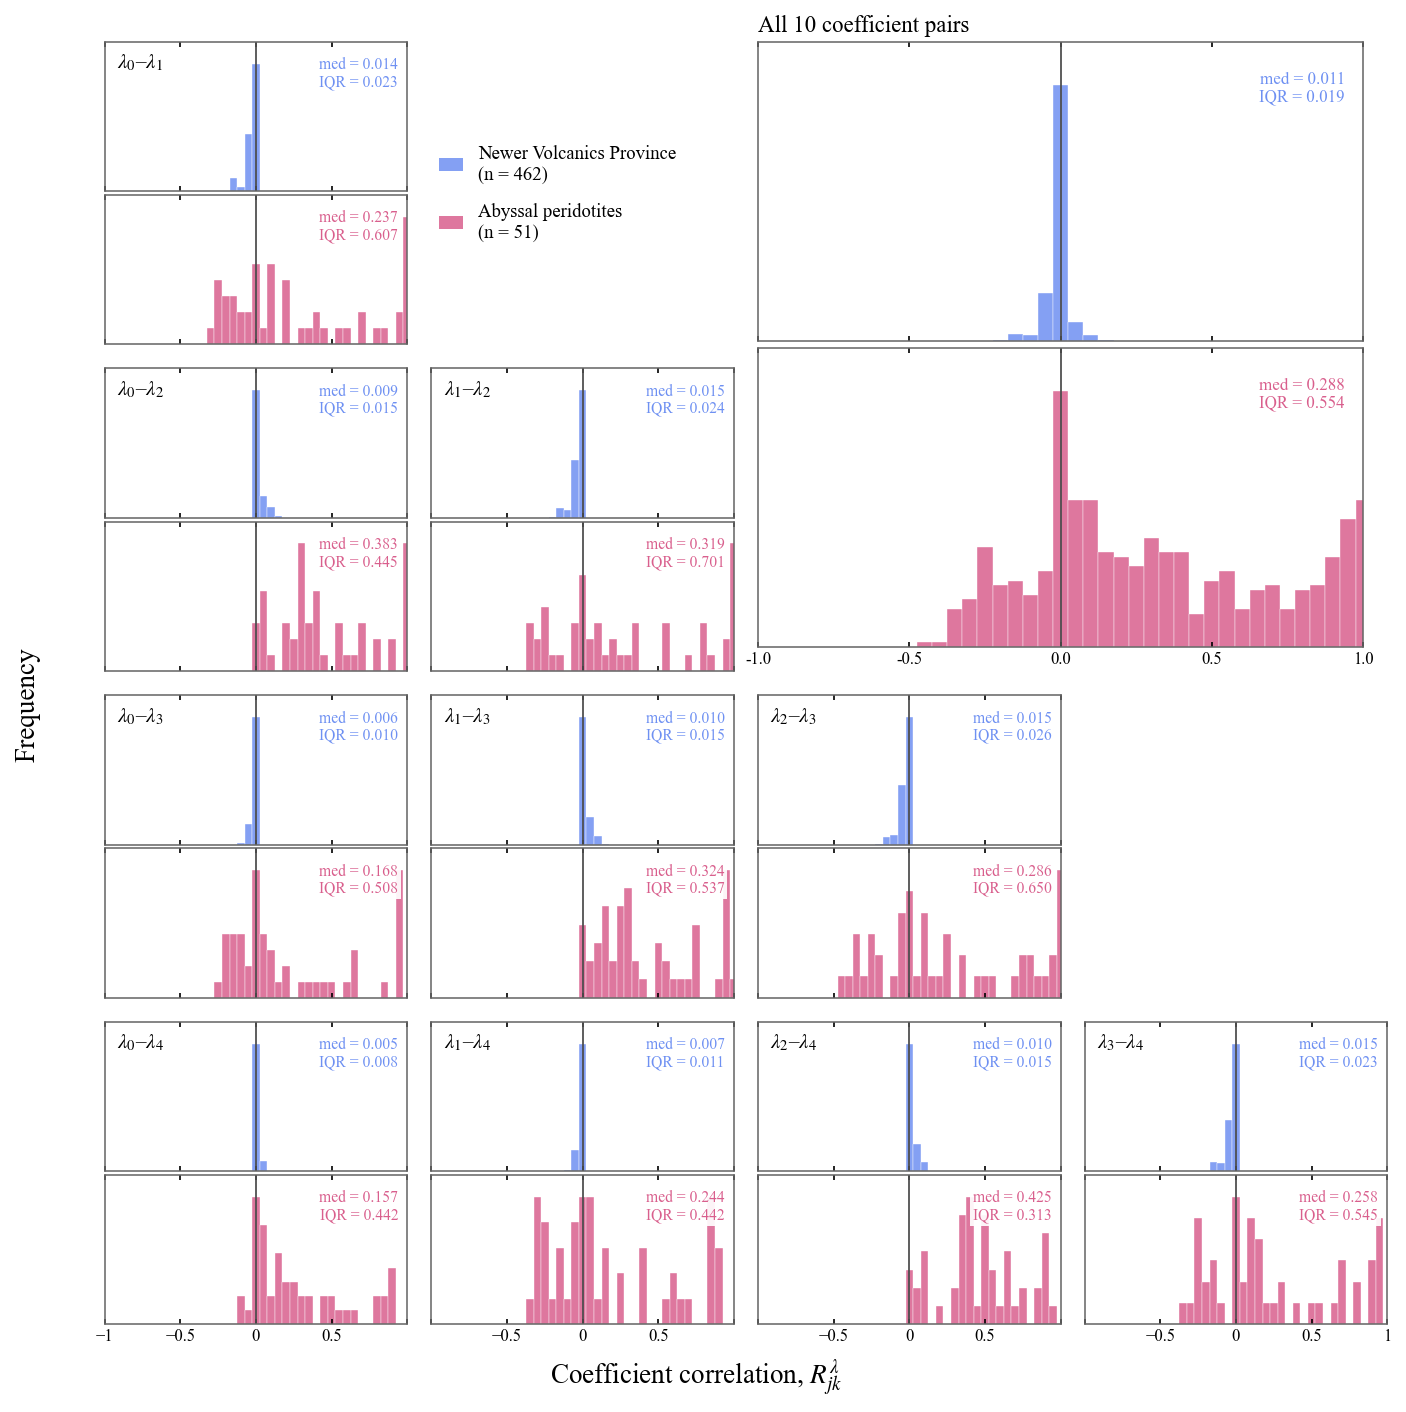

In [6]:
# Figure 3.4
pairs = [(j, k) for j in range(5) for k in range(j + 1, 5)]
rjk = pd.DataFrame([{"sample_id": r.sample_id, "dataset": r.dataset, "j": j, "k": k,
                     "R": getattr(r, f"lambda_cov_{j}{k}") / np.sqrt(getattr(r, f"lambda_cov_{j}{j}") * getattr(r, f"lambda_cov_{k}{k}"))}
                    for r in combined_lambda.itertuples() for j, k in pairs])
rjk["abs_R"] = rjk["R"].abs()
display(rjk.groupby(["j", "k", "dataset"])["abs_R"].agg(["mean", "median", "max"]).unstack("dataset").round(3))
for name, g in rjk.groupby("dataset", sort=False):
    print(f"{name}: median |R| = {g.abs_R.median():.3f}, IQR = {iqr_of(g.abs_R):.3f}, max |R| = {g.abs_R.max():.3f}")

X_VIEW, BIN_W, XTICKS = 1.0, .05, [-1., -.5, 0., .5, 1.]
bins = np.arange(-X_VIEW - BIN_W / 2, X_VIEW + BIN_W, BIN_W)
pct = lambda v: 100 * np.histogram(v, bins=bins)[0] / len(v)
stats = lambda v: (v.median(), v.quantile(.75) - v.quantile(.25))


def split_square(fig, box, gap=.012):
    x0, y0, w, h = box
    half = h * (1 - gap) / 2
    top = fig.add_axes([x0, y0 + h - half, w, half])
    return top, fig.add_axes([x0, y0, w, half], sharex=top)


def draw_hist(ax, g, colour, pair=None, show_ticks=False, pooled=False):
    heights = pct(g["R"].to_numpy())
    ax.bar(bins[:-1], heights, width=np.diff(bins), align="edge", color=colour, alpha=.85, edgecolor="white", linewidth=.22)
    ax.axvline(0, color="0.30", ls="-", lw=.85)
    ax.set(xlim=(-X_VIEW, X_VIEW), ylim=(0, max(1., heights.max() * 1.17)))
    ax.set_xticks(XTICKS)
    ax.tick_params(axis="x", direction="in", top=True, length=2.5, pad=2, labelsize=8, labelbottom=show_ticks)
    ax.tick_params(axis="y", left=False, right=False, labelleft=False, labelright=False)
    for spine in ax.spines.values():
        spine.set(color="0.4", linewidth=.75)
    med, iqr = stats(g["abs_R"])
    ax.text(.97, .90, f"med = {med:.3f}\nIQR = {iqr:.3f}", transform=ax.transAxes, ha="right", va="top",
            fontsize=8.2 if pooled else 7.5, color=colour, linespacing=1.12,
            bbox=dict(facecolor="white", edgecolor="none", alpha=.93, pad=1.1))
    if pair is not None:
        ax.text(.04, .93, rf"$\lambda_{{{pair[0]}}}$–$\lambda_{{{pair[1]}}}$", transform=ax.transAxes, ha="left",
                va="top", fontsize=10)


with plt.rc_context({**THESIS_RC, "font.size": 11}):
    fig = plt.figure(figsize=(9.5, 9.5))
    gs = fig.add_gridspec(4, 4, left=.085, right=.985, bottom=.065, top=.965, wspace=.08, hspace=.08)
    for k in range(1, 5):
        for j in range(k):
            for row, (ax, (name, (_, colour))) in enumerate(zip(split_square(fig, gs[k - 1, j].get_position(fig).bounds),
                                                                DATA_STYLE.items())):
                draw_hist(ax, rjk[(rjk.dataset == name) & (rjk.j == j) & (rjk.k == k)], colour,
                          pair=(j, k) if row == 0 else None, show_ticks=(k == 4 and row == 1))
                if k == 4 and row == 1:
                    ax.set_xticklabels(["" if j > 0 else "−1", "−0.5", "0", "0.5", "" if j < 3 else "1"])
    base = gs[0, 2].get_position(fig)
    big = (base.x0, base.y1 - base.height * 2, base.width * 2, base.height * 2)
    pooled = split_square(fig, big)
    for row, (ax, (name, (_, colour))) in enumerate(zip(pooled, DATA_STYLE.items())):
        draw_hist(ax, rjk[rjk.dataset == name], colour, show_ticks=(row == 1), pooled=True)
    pooled[0].set_title("All 10 coefficient pairs", loc="left", pad=5, fontsize=11)
    leg_ax = fig.add_axes(gs[0, 1].get_position(fig).bounds)
    leg_ax.axis("off")
    n_by = rjk.groupby("dataset")["sample_id"].nunique()
    leg_ax.legend(handles=[Patch(facecolor=c, alpha=.85, label=f"{label}\n(n = {n_by.get(name, 0)})")
                           for name, (label, c) in DATA_STYLE.items()], frameon=False, loc="center left",
                  bbox_to_anchor=(0, .5), fontsize=9, labelspacing=1.0, handlelength=1.3, borderaxespad=0)
    fig.supxlabel(r"Coefficient correlation, $R^\lambda_{jk}$", y=.014, fontsize=13)
    fig.supylabel("Frequency", x=.022, fontsize=13)
    fig.savefig(FIGURES_DIR / "R_lambda_jk_histograms_by_pair.pdf", bbox_inches="tight", facecolor="white")
    fig.savefig(FIGURES_DIR / "R_lambda_jk_histograms_by_pair.png", dpi=300, bbox_inches="tight", facecolor="white")
    plt.show()

2026-10-30 14:33:13,704 pyrolite.util.plot.helpers - WARNING: scikit-learn not installed


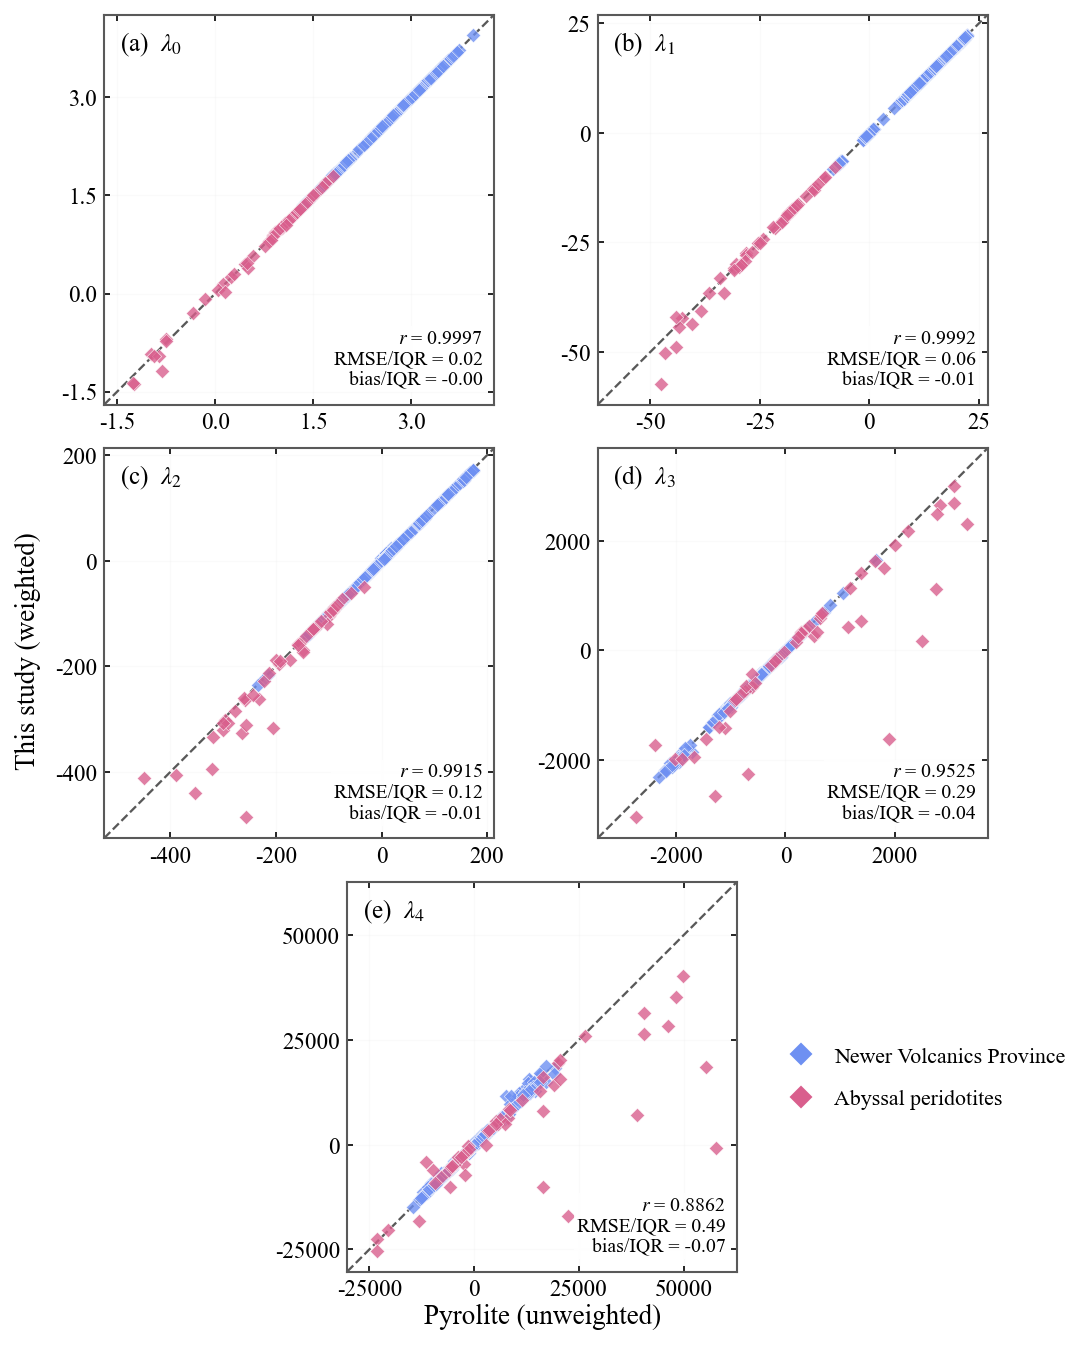

,lambda,dataset,n,r,RMSE/IQR,bias/IQR
0,lambda0,all,513,0.9997,0.0170,-0.0004
1,lambda0,NVP,462,1.0000,0.0022,0.0009
2,lambda0,Abyssal LA-ICP-MS,51,0.9975,0.0536,-0.0124
3,lambda1,all,513,0.9992,0.0610,-0.0068
4,lambda1,NVP,462,1.0000,0.0048,-0.0016
5,lambda1,Abyssal LA-ICP-MS,51,0.9916,0.1930,-0.0539
6,lambda2,all,513,0.9915,0.1206,-0.0138
7,lambda2,NVP,462,1.0000,0.0069,0.0005
8,lambda2,Abyssal LA-ICP-MS,51,0.9400,0.3820,-0.1430
9,lambda3,all,513,0.9525,0.2924,-0.0353


In [7]:
# Figure 3.6
import pyrolite.geochem

lp = combined_ree[REE].pyrochem.lambda_lnREE(norm_to=CI, exclude=[], params="full", degree=5, scale="ppm", algorithm="ONeill")
lp.index = combined_ree["sample_id"].values
study, dataset = combined_lambda.set_index("sample_id"), combined_ree.set_index("sample_id")["dataset"]
metrics = []
with plt.rc_context({**THESIS_RC, "font.size": 12, "xtick.labelsize": 11, "ytick.labelsize": 11}):
    W, H, SIDE = 7.4, 9.2, 2.6
    fig = plt.figure(figsize=(W, H))
    corners = [(0.78, 6.24), (4.07, 6.24), (0.78, 3.35), (4.07, 3.35), ((W - SIDE) / 2, 0.46)]
    for k, (x0, y0) in enumerate(corners):
        ax = fig.add_axes([x0 / W, y0 / H, SIDE / W, SIDE / H])
        pair = pd.DataFrame({"pyrolite": pd.to_numeric(lp[f"λ{k}"], errors="coerce"), "study": study[f"lambda{k}"]}).join(dataset).dropna()
        spread = iqr_of(pair["study"])
        for name, sub in [("all", pair)] + list(pair.groupby("dataset", sort=False)):
            diff = sub["study"] - sub["pyrolite"]
            metrics.append({"lambda": f"lambda{k}", "dataset": name, "n": len(sub), "r": np.corrcoef(sub["pyrolite"], sub["study"])[0, 1],
                            "RMSE/IQR": np.sqrt(np.mean(diff ** 2)) / spread, "bias/IQR": diff.mean() / spread})
        m = next(x for x in metrics if x["lambda"] == f"lambda{k}" and x["dataset"] == "all")
        for name, sub in pair.groupby("dataset", sort=False):
            ax.scatter(sub["pyrolite"], sub["study"], s=24, marker="D", color=DATA_STYLE[name][1], alpha=0.8,
                       edgecolor="white", linewidth=0.3, zorder=3)
        lo, hi = pair[["pyrolite", "study"]].min().min(), pair[["pyrolite", "study"]].max().max()
        pad = 0.06 * (hi - lo if hi > lo else 1)
        ax.plot([lo - pad, hi + pad], [lo - pad, hi + pad], "--", color="0.35", lw=1.1)
        ax.set(xlim=(lo - pad, hi + pad), ylim=(lo - pad, hi + pad))
        ax.set_aspect("equal", adjustable="box")
        ax.text(0.04, 0.96, rf"({chr(97 + k)})  $\lambda_{k}$", transform=ax.transAxes, ha="left", va="top", fontsize=12)
        ax.text(0.97, 0.04, rf"$r$ = {m['r']:.4f}" + "\n" + rf"RMSE/IQR = {m['RMSE/IQR']:.2f}" + "\n"
                + rf"bias/IQR = {m['bias/IQR']:.2f}", transform=ax.transAxes, ha="right", va="bottom",
                fontsize=9.5, bbox=dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5))
        ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
        ax.tick_params(direction="in", top=True, right=True, length=3)
        ax.grid(alpha=0.15)
        ax.set_axisbelow(True)
    fig.legend(handles=[Line2D([], [], marker="D", ls="", color=c, markersize=7, label=label) for label, c in DATA_STYLE.values()],
               loc="center left", bbox_to_anchor=(5.15 / W, 1.75 / H), bbox_transform=fig.transFigure,
               frameon=False, fontsize=10.5, labelspacing=1.0, handletextpad=0.5)
    fig.text(0.5, 0.012, "Pyrolite (unweighted)", ha="center", fontsize=13)
    fig.text(0.025, 0.5, "This study (weighted)", va="center", rotation=90, fontsize=13)
    fig.savefig(FIGURES_DIR / "pyrolite_vs_weighted_lambda.pdf", bbox_inches="tight", facecolor="white")
    plt.show()
display(pd.DataFrame(metrics).round(4))

In [8]:
# Table 3.1
lam_base = combined_lambda[LAMBDA_COLS].to_numpy()
display(pd.DataFrame({lod: 100 * np.median(np.abs(np.array([fit_lambda(p, lod_sigma_ppm=lod)["lambdas"] for p in ppm_all])
                                                    - lam_base), axis=0) / POPULATION_IQR.to_numpy()
                      for lod in (0.003, 0.010)}, index=LAMBDA_COLS).T.rename_axis("sigma_LOD (ppm)").round(2))

OMIT = {e: (e,) for e in REE}
OMIT.update({"La–Ce–Pr": ("La", "Ce", "Pr"), "La–Ce": ("La", "Ce"), "Tm–Yb–Lu": ("Tm", "Yb", "Lu"),
             "Yb–Lu": ("Yb", "Lu"), "Sm–Eu": ("Sm", "Eu"), "Tb–Dy": ("Tb", "Dy")})
records = []
for label, omit in OMIT.items():
    idx = [REE.index(e) for e in omit]
    for i, ppm in enumerate(ppm_all):
        measured = np.isfinite(ppm) & (ppm > 0)
        if measured[idx].all() and measured.sum() - len(omit) >= MIN_REE:
            records.append({"REE omitted": label, **dict(zip(LAMBDA_COLS, np.abs(fit_lambda(ppm, exclude=omit)["lambdas"] - lam_base[i])))})
omission = pd.DataFrame(records).groupby("REE omitted", sort=False)
display((100 * omission.median() / POPULATION_IQR.set_axis(LAMBDA_COLS)).assign(n=omission.size()).round(2))

,lambda0,lambda1,lambda2,lambda3,lambda4
sigma_LOD (ppm),,,,,
0.003,0.02,0.04,0.05,0.21,0.64
0.010,0.08,0.18,0.21,0.81,2.38


,lambda0,lambda1,lambda2,lambda3,lambda4,n
REE omitted,,,,,,
La,0.94,3.89,6.73,18.78,27.55,510
Ce,0.32,1.11,1.01,0.78,7.63,511
Pr,0.15,0.42,0.01,2.11,4.26,493
Nd,0.15,0.32,0.36,2.75,1.74,513
Sm,0.30,0.26,1.32,2.71,6.64,513
Eu,0.26,0.10,1.18,0.61,6.52,513
Gd,0.34,0.04,1.49,1.42,6.81,513
Tb,0.28,0.16,1.06,2.70,2.03,509
Dy,0.22,0.24,0.62,2.84,1.91,513


,n,median,mean,IQR,within 10% (%),within 20% (%)
all,513.0,1.000,0.997,0.086,80.897,96.881
Abyssal LA-ICP-MS,51.0,0.934,0.925,0.125,58.824,90.196
NVP,462.0,1.005,1.004,0.082,83.333,97.619


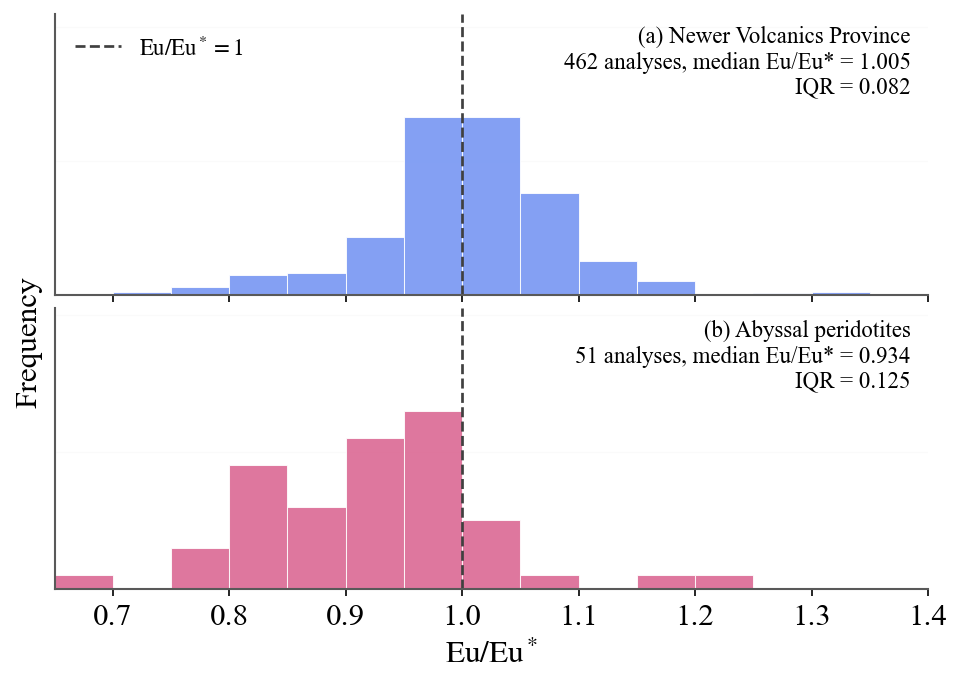

In [9]:
# Figure 3.2
eu = combined_ree[["dataset", "Sm", "Eu", "Gd"]].dropna().copy()
eu["Eu_Eu_star"] = (eu["Eu"] / CI[5]) / np.sqrt((eu["Sm"] / CI[4]) * (eu["Gd"] / CI[6]))
summary = lambda v: pd.Series({"n": len(v), "median": v.median(), "mean": v.mean(), "IQR": iqr_of(v),
                               "within 10% (%)": 100 * v.between(0.9, 1.1).mean(), "within 20% (%)": 100 * v.between(0.8, 1.2).mean()})
display(pd.DataFrame({"all": summary(eu["Eu_Eu_star"]), **{n: summary(g["Eu_Eu_star"]) for n, g in eu.groupby("dataset")}}).T.round(3))

lo, hi = eu["Eu_Eu_star"].min(), eu["Eu_Eu_star"].max()
BIN_W = 0.02 if hi - lo <= 0.6 else 0.05 if hi - lo <= 1.5 else 0.1
TICK = 0.1 if hi - lo <= 0.8 else 0.2 if hi - lo <= 1.6 else 0.5
X_MIN, X_MAX = np.floor((lo - BIN_W / 2) / BIN_W) * BIN_W, np.ceil((hi + BIN_W / 2) / BIN_W) * BIN_W
bins = np.arange(X_MIN, X_MAX + BIN_W * 0.5, BIN_W)
with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(len(DATA_STYLE), 1, figsize=(6.3, 2.0 * len(DATA_STYLE) + 0.4), sharex=True, layout="constrained")
    fig.get_layout_engine().set(h_pad=0.02, hspace=0.01)
    for i, (ax, (name, (label, colour))) in enumerate(zip(axes, DATA_STYLE.items())):
        r = eu.loc[eu["dataset"] == name, "Eu_Eu_star"].to_numpy()
        ax.hist(r, bins=bins, color=colour, alpha=0.85, edgecolor="white", linewidth=0.5)
        ax.axvline(1, color="0.25", ls="--", lw=1.3, label=r"$\mathrm{Eu/Eu^*}=1$")
        ax.set_ylim(0, ax.get_ylim()[1] * 1.5)
        ax.text(0.98, 0.96, f"({chr(97 + i)}) {label}\n{len(r)} analyses, median Eu/Eu* = {np.median(r):.3f}\n"
                f"IQR = {iqr_of(r):.3f}", transform=ax.transAxes, ha="right", va="top", fontsize=11, zorder=10)
        ax.tick_params(axis="y", left=False, right=False, labelleft=False, labelright=False)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.15)
        ax.set_axisbelow(True)
    axes[0].legend(frameon=False, fontsize=11, loc="upper left")
    axes[-1].set(xlim=(X_MIN, X_MAX), xlabel=r"$\mathrm{Eu/Eu^*}$")
    axes[-1].xaxis.set_major_locator(MultipleLocator(TICK))
    fig.supylabel("Frequency", fontsize=15)
    fig.savefig(FIGURES_DIR / "eu_anomaly_distribution.pdf", bbox_inches="tight", facecolor="white")
    plt.show()

In [10]:
# Monte Carlo uncertainty propagation
N_ITER, MC_MAX_SIGMA_LN = 10_000, 1.0
MC_MASKS = combined_ree[REE].notna().to_numpy()


def run_monte_carlo(noise="random", sigma_is=0.10, seed=42):
    rng = np.random.default_rng(seed)
    lam = combined_lambda[LAMBDA_COLS].to_numpy(float)
    rows = []
    with np.errstate(all="ignore"):
        for _ in range(N_ITER):
            pick = rng.integers(len(lam))
            lam_in, keep = lam[pick], MC_MASKS[pick].copy()
            ppm_true = reconstruct_ppm(lam_in)
            sigma = sigma_ln_from_ppm(ppm_true)
            shift = rng.normal(0, sigma) if noise == "random" else rng.normal(0, sigma_is)
            keep &= sigma <= MC_MAX_SIGMA_LN
            try:
                rows.append(fit_lambda(np.where(keep, ppm_true * np.exp(shift), np.nan))["lambdas"] - lam_in)
            except ValueError:
                pass
    return pd.DataFrame(rows, columns=[f"delta_lambda{k}" for k in range(5)])


mc_random = run_monte_carlo("random", seed=42)
mc_systematic = {s: run_monte_carlo("systematic", s, seed) for s, seed in [(0.01, 43), (0.05, 44), (0.10, 45)]}
print("IQR(delta lambda) / population IQR:")
display(pd.DataFrame({name: [iqr_of(mc[f"delta_lambda{k}"]) / POPULATION_IQR[k] for k in range(5)]
                      for name, mc in [("random", mc_random)] + [(f"systematic {s:.0%}", m) for s, m in mc_systematic.items()]},
                     index=LAMBDA_COLS).T.round(4))

IQR(delta lambda) / population IQR:


,lambda0,lambda1,lambda2,lambda3,lambda4
random,0.0309,0.0715,0.1216,0.3548,0.6542
systematic 1%,0.0109,0.0000,0.0000,0.0000,0.0000
systematic 5%,0.0551,0.0000,0.0000,0.0000,0.0000
systematic 10%,0.1095,0.0000,0.0000,0.0000,0.0000


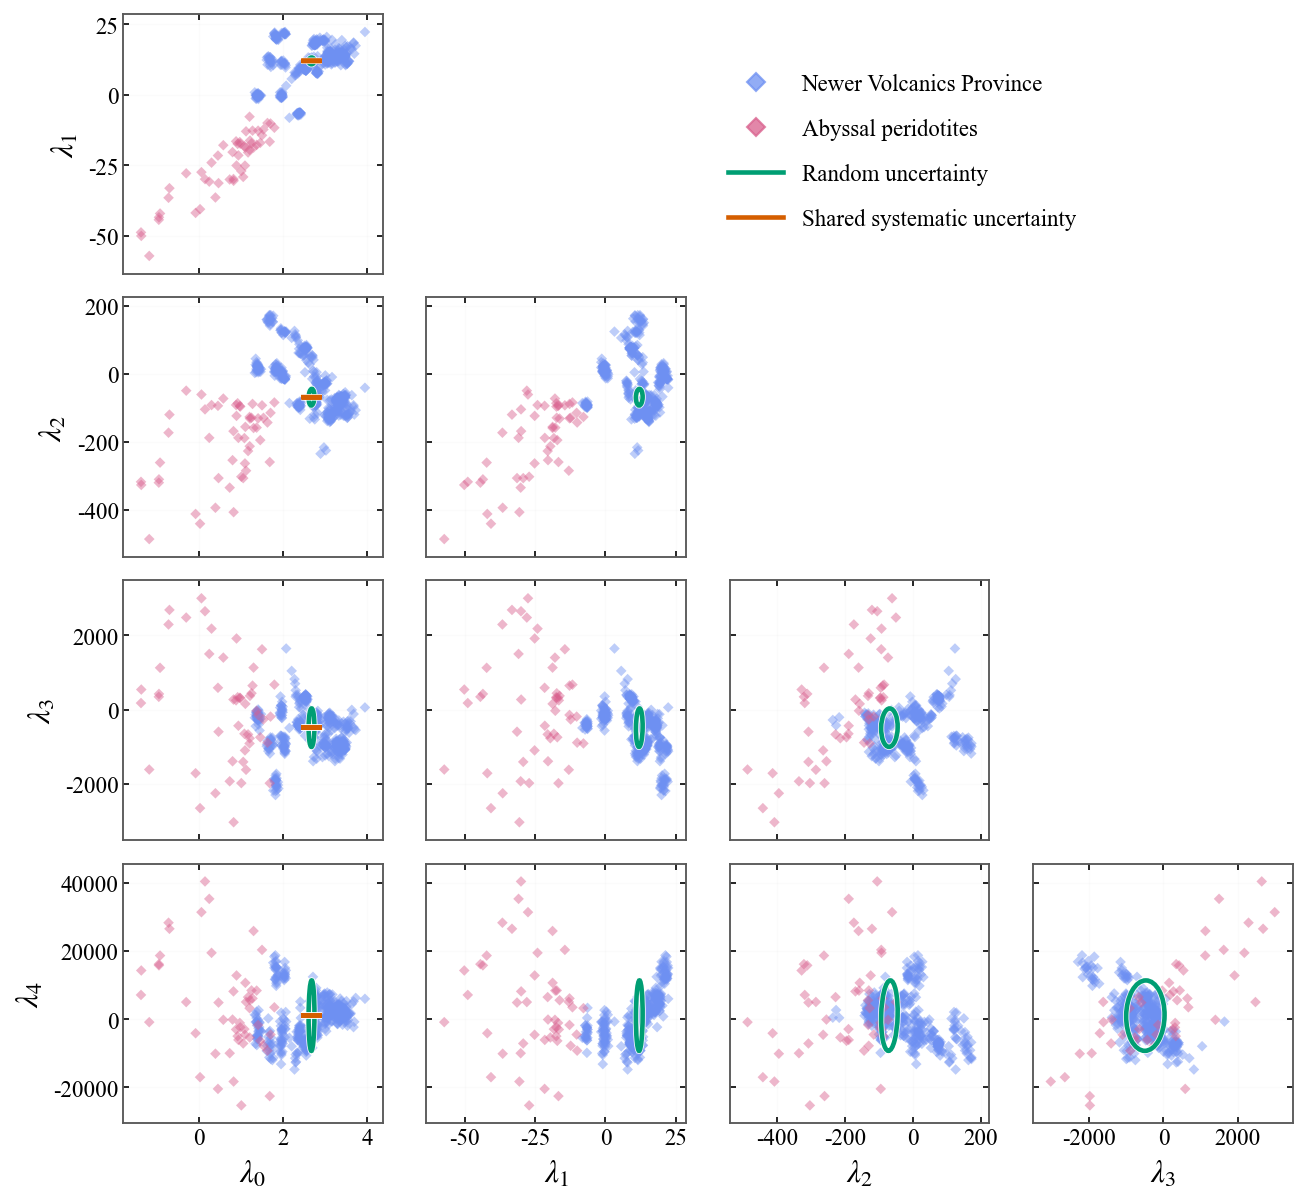

In [11]:
# Figure 3.8
K95 = np.sqrt(chi2.ppf(0.95, df=2))
HALO = [pe.Stroke(linewidth=3, foreground="white", alpha=0.9), pe.Normal()]


def robust_cov(xy):
    s = np.array([iqr_of(xy[:, 0]), iqr_of(xy[:, 1])]) / 1.349
    rho = spearmanr(xy[:, 0], xy[:, 1])[0] if s.min() > 0 else 0.0
    r = 2 * np.sin(np.pi * rho / 6) if np.isfinite(rho) else 0.0
    return np.array([[s[0] ** 2, r * s[0] * s[1]], [r * s[0] * s[1], s[1] ** 2]])


def ellipse95(centre, cov, **style):
    vals, vecs = np.linalg.eigh(cov)
    vals, vecs = np.clip(vals[::-1], 0, None), vecs[:, ::-1]
    width, height = 2 * K95 * np.sqrt(vals)
    return Ellipse(centre, width, height, angle=np.degrees(np.arctan2(vecs[1, 0], vecs[0, 0])), **style)


def finite(frame, cols):
    xy = frame[cols].to_numpy(float)
    return xy[np.isfinite(xy).all(axis=1)]

with plt.rc_context({**THESIS_RC, "font.size": 12, "xtick.labelsize": 11, "ytick.labelsize": 11}):
    fig = plt.figure(figsize=(9.0, 8.5))
    gs = fig.add_gridspec(4, 4, left=0.10, right=0.98, bottom=0.10, top=0.97, wspace=0.09, hspace=0.09)
    for i in range(1, 5):
        for j in range(i):
            ax = fig.add_subplot(gs[i - 1, j])
            cols = [f"lambda{j}", f"lambda{i}"]
            xy = finite(combined_lambda, cols)
            for name, (_, colour) in DATA_STYLE.items():
                ax.scatter(*finite(combined_lambda[combined_lambda["dataset"] == name], cols).T, marker="D", s=13,
                           facecolor=colour, edgecolor="none", alpha=0.45, zorder=2)
            for mc, key in [(mc_random, "random_unc")] + ([(mc_systematic[0.10], "systematic_unc")] if j == 0 else []):
                ax.add_patch(ellipse95(np.median(xy, axis=0), robust_cov(finite(mc, [f"delta_lambda{j}", f"delta_lambda{i}"])),
                                       facecolor="none", edgecolor=UNC_COL[key], lw=2.2, path_effects=HALO, zorder=5))
            pad = 0.08 * np.where(np.ptp(xy, axis=0) > 0, np.ptp(xy, axis=0), 1)
            lo, hi = xy.min(axis=0) - pad, xy.max(axis=0) + pad
            ax.set(xlim=(lo[0], hi[0]), ylim=(lo[1], hi[1]), box_aspect=1)
            ax.xaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.yaxis.set_major_locator(MaxNLocator(nbins=4))
            ax.tick_params(direction="in", top=True, right=True, length=3, pad=2, labelsize=11,
                           labelbottom=(i == 4), labelleft=(j == 0))
            ax.grid(alpha=0.12)
            ax.set_axisbelow(True)
            for spine in ax.spines.values():
                spine.set(color="0.35", linewidth=0.9)
            if j == 0:
                ax.set_ylabel(rf"$\lambda_{i}$", fontsize=15)
            if i == 4:
                ax.set_xlabel(rf"$\lambda_{j}$", fontsize=15)
    handles = ([Line2D([], [], marker="D", ls="", color=c, alpha=0.75, markersize=6, label=label) for label, c in DATA_STYLE.values()]
               + [Line2D([], [], color=UNC_COL["random_unc"], lw=2.2, label="Random uncertainty"),
                  Line2D([], [], color=UNC_COL["systematic_unc"], lw=2.2, label="Shared systematic uncertainty")])
    fig.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.54, 0.94), frameon=False, fontsize=11,
               handlelength=2.4, labelspacing=1.0)
    fig.savefig(FIGURES_DIR / "lambda_monte_carlo_envelopes.pdf", bbox_inches="tight", facecolor="white")
    plt.show()

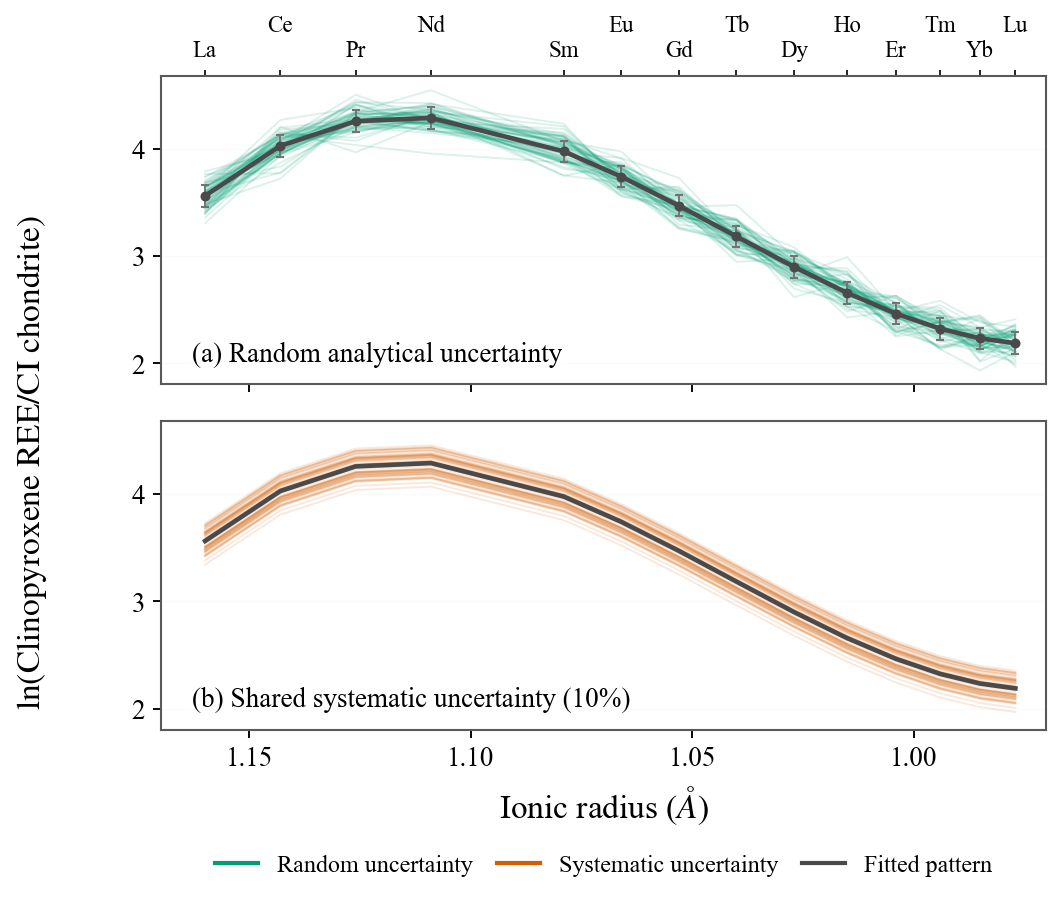

In [12]:
# Figure 3.7
SAMPLE, SIGMA_SYS, N_DRAWS = "76999 - 14 [1]", 0.10, 60
ppm = ree_by_id.loc[SAMPLE, REE].to_numpy(float)
fit = fit_lambda(ppm)
good = np.isfinite(ppm) & (ppm > 0)
x, elements = IONIC_RADII[good], np.array(REE)[good]
y_fit = full_ree_basis(x) @ fit["lambdas"]
rng = np.random.default_rng(3)
draws = {"random_unc": y_fit + rng.normal(0, fit["sigma"], (N_DRAWS, len(x))),
         "systematic_unc": y_fit + rng.normal(0, SIGMA_SYS, (N_DRAWS, 1))}

with plt.rc_context(THESIS_RC):
    fig, axes = plt.subplots(2, 1, figsize=(7.2, 6.6), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.16, right=0.98, top=0.89, bottom=0.23, hspace=0.12)
    for ax, title, key in zip(axes, ["(a) Random analytical uncertainty", "(b) Shared systematic uncertainty (10%)"], draws):
        ax.plot(x, draws[key].T, color=UNC_COL[key], alpha=0.14, lw=0.9, zorder=1)
        ax.plot(x, y_fit, color=COL["data"], lw=2.2, zorder=3)
        ax.text(0.035, 0.055, title, transform=ax.transAxes, ha="left", va="bottom", fontsize=13, weight="medium",
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.90, pad=2), zorder=10)
        ax.set_xlim(1.17, 0.97)
        ax.grid(axis="y", alpha=0.15)
        ax.set_axisbelow(True)
        ax.tick_params(direction="out", length=4, width=0.9, labelsize=13)
        for spine in ax.spines.values():
            spine.set(color="0.35", linewidth=1.0)
    axes[0].errorbar(x, y_fit, yerr=fit["sigma"], fmt="o", ms=3.8, color=COL["data"], ecolor="0.45", elinewidth=0.9, capsize=2, zorder=4)
    axes[1].set_xticks([1.15, 1.10, 1.05, 1.00])
    top = axes[0].secondary_xaxis("top")
    top.set_xticks(x, labels=[])
    top.tick_params(direction="out", length=3)
    top.spines["top"].set_visible(False)
    for i, (element, radius) in enumerate(zip(elements, x)):
        axes[0].annotate(element, (radius, 1), xycoords=("data", "axes fraction"), xytext=(0, 7 if i % 2 == 0 else 19),
                         textcoords="offset points", ha="center", va="bottom", fontsize=11, annotation_clip=False)
    axes[1].set_xlabel(r"Ionic radius ($\AA$)", fontsize=16, labelpad=6)
    fig.supylabel(r"$\ln(\mathrm{Clinopyroxene\ REE}/\mathrm{CI\ chondrite})$", x=0.025, fontsize=16)
    fig.legend(handles=[Line2D([], [], color=UNC_COL["random_unc"], lw=2, label="Random uncertainty"),
                        Line2D([], [], color=UNC_COL["systematic_unc"], lw=2, label="Systematic uncertainty"),
                        Line2D([], [], color=COL["data"], lw=2, label="Fitted pattern")],
               loc="lower center", bbox_to_anchor=(0.57, 0.06), ncol=3, frameon=False, fontsize=11.5, handlelength=1.8,
               columnspacing=1.0)
    fig.savefig(FIGURES_DIR / "sample_uncertainty_random_vs_systematic.pdf", bbox_inches="tight", facecolor="white")
    plt.show()

In [13]:
# Lambda uncertainty used in Chapters 5 to 7
import json

UNC_DEGREE = 3
UNC_FILE = PROJECT_DIR / "ch3_lambda_uncertainty.json"

lam_unc_in = np.array([fit_lambda(p, degree=UNC_DEGREE)["lambdas"] for p in ppm_all])
rng = np.random.default_rng(46)
deltas = []
with np.errstate(all="ignore"):
    for _ in range(N_ITER):
        pick = rng.integers(len(lam_unc_in))
        lam_in, keep = lam_unc_in[pick], MC_MASKS[pick].copy()
        ppm_true = reconstruct_ppm(lam_in)
        sigma = sigma_ln_from_ppm(ppm_true)
        keep &= sigma <= MC_MAX_SIGMA_LN
        try:
            refit = fit_lambda(np.where(keep, ppm_true * np.exp(rng.normal(0, sigma)), np.nan), degree=UNC_DEGREE)
            deltas.append(refit["lambdas"] - lam_in)
        except ValueError:
            pass
deltas = np.array(deltas)
deltas = deltas[np.isfinite(deltas).all(axis=1)]

n_lam = UNC_DEGREE + 1
s_random = np.array([iqr_of(deltas[:, a]) for a in range(n_lam)]) / 1.349
r_random = np.eye(n_lam)
for a in range(n_lam):
    for b in range(a + 1, n_lam):
        r_random[a, b] = r_random[b, a] = 2 * np.sin(np.pi * spearmanr(deltas[:, a], deltas[:, b])[0] / 6)
cov_random = r_random * np.outer(s_random, s_random)
s_systematic = iqr_of(mc_systematic[0.10]["delta_lambda0"]) / 1.349
cov_total = cov_random.copy()
cov_total[0, 0] += s_systematic ** 2

UNC_FILE.write_text(json.dumps({
    "degree": UNC_DEGREE, "k95": float(K95), "n_iterations": int(len(deltas)),
    "sigma_random": s_random.tolist(), "sigma_systematic_lambda0": float(s_systematic),
    "cov_total": cov_total.tolist(), "ionic_radii": IONIC_RADII.tolist(), "ci": CI.tolist(),
    "note": "95% ellipse = K95 x sqrt(eigenvalues of cov_total); random (degree-3 refits) + 10% systematic on lambda0"},
    indent=2))
s_degree4 = np.array([iqr_of(mc_random[f"delta_lambda{a}"]) for a in range(n_lam)]) / 1.349
display(pd.DataFrame({"random, degree-3 refit": s_random, "random, degree-4 refit (Section 7)": s_degree4,
                      "total (random + systematic)": np.sqrt(np.diag(cov_total)),
                      "total / population IQR (%)": 100 * np.sqrt(np.diag(cov_total)) / POPULATION_IQR.to_numpy()[:n_lam]},
                     index=LAMBDA_COLS[:n_lam]).round(4))

,"random, degree-3 refit","random, degree-4 refit (Section 7)",total (random + systematic),total / population IQR (%)
lambda0,0.0283,0.0283,0.1041,8.4319
lambda1,0.5039,0.4893,0.5039,5.4569
lambda2,9.8941,9.9354,9.8941,8.9776
lambda3,204.8640,211.9746,204.8640,25.4201
